# XGBoost — dự báo giáng thủy trong 60 phút tới

Mô hình thứ hai của AIoT Plant Care. Chạy CPU Colab là đủ; không cần dùng GPU.
CSV hiện có chứa `precipitation` (mưa + tuyết), nên đây là **nhãn đại diện cho mưa**.
Nhãn tại `t`: tổng giáng thủy `(t,t+60 phút] >= 0.1 mm`, lấy từ dòng `t+1h`.
Chỉ dùng đặc trưng tại hoặc trước `t`. Không dùng độ ẩm đất để đoán thay khí tượng.
**Run All chỉ chạy audit và smoke; full training và Test mặc định tắt.**


## 1. Chuẩn bị Colab CPU

Đóng gói bằng `scripts/package-colab.ps1`. Upload source ZIP và `open-meteo.csv`
vào `MyDrive/aiot-plant-care/`. Mở notebook trên hosted Colab Python 3.12,
chọn CPU runtime; không cần dành GPU cho XGBoost.
Bootstrap giữ Torch của runtime, cài dependency bổ sung; restart session nếu được yêu cầu.


In [1]:
from pathlib import Path
import os
import sys
import hashlib
import zipfile
import importlib

if sys.platform != "linux":
    raise RuntimeError("Chọn hosted runtime Google Colab; không dùng kernel Windows/local.")
try:
    from google.colab import drive
except ImportError as error:
    raise RuntimeError("Notebook yêu cầu hosted runtime Google Colab.") from error
drive.mount("/content/drive")
DRIVE_ROOT = Path(os.getenv("COLAB_DRIVE_ROOT", "/content/drive/MyDrive/aiot-plant-care"))
SOURCE_ZIP = DRIVE_ROOT / "aiot-ml-colab.zip"
if not SOURCE_ZIP.is_file():
    raise FileNotFoundError(f"Upload ZIP mã nguồn trước: {SOURCE_ZIP}")
with SOURCE_ZIP.open("rb") as stream:
    source_hash = hashlib.file_digest(stream, "sha256").hexdigest()
ML_ROOT = Path("/content") / f"aiot-ml-{source_hash[:12]}"
ready = ML_ROOT / ".ready"
if not ready.exists():
    if ML_ROOT.exists() and any(ML_ROOT.iterdir()):
        raise RuntimeError("Source giải nén dở; dùng runtime mới, không trộn source.")
    with zipfile.ZipFile(SOURCE_ZIP) as archive:
        if sum(item.file_size for item in archive.infolist()) > 50 * 1024**2:
            raise ValueError("Source ZIP quá lớn; không đóng kèm dataset/weights.")
        for item in archive.infolist():
            target = (ML_ROOT / item.filename).resolve()
            if (not target.is_relative_to(ML_ROOT) or chr(92) in item.orig_filename
                    or (item.external_attr >> 16) & 0o170000 == 0o120000):
                raise ValueError("Source ZIP có đường dẫn không hợp lệ hoặc symlink")
        archive.extractall(ML_ROOT)
    ready.write_text(source_hash, encoding="utf-8")
sys.path.insert(0, str(ML_ROOT))
if "colab_runtime" in sys.modules and Path(sys.modules["colab_runtime"].__file__).resolve() != ML_ROOT / "colab_runtime.py":
    raise RuntimeError("Source ZIP changed: restart session before continuing.")
colab_runtime = importlib.import_module("colab_runtime")
prepare_runtime = colab_runtime.prepare_runtime
extract_zip_once = colab_runtime.extract_zip_once

INSTALL_DEPS = True  # Nếu thư viện đã đúng lock, không cài lại.
RUNTIME_INFO = prepare_runtime(ML_ROOT, require_gpu=False, install=INSTALL_DEPS)
CODE_ROOT = ML_ROOT / "weather"
sys.path.insert(0, str(CODE_ROOT))
os.chdir(CODE_ROOT)
print("Kernel Colab:", sys.executable, "| Source SHA256:", source_hash)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "python": "3.12.13",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "cuda": "12.8",
  "device": "CPU Colab"
}
Kernel Colab: /usr/bin/python3 | Source SHA256: 5aeff8959d22dca2002dc7fce54b37ae19e2f9943fed5a5d9a1909bc453e0695


## 2. Đọc CSV sẵn có hoặc tải Open-Meteo trực tiếp

Mặc định đọc CSV của dự án. `DATA_SOURCE="download"` tải từ Open-Meteo theo từng năm.
Tọa độ mặc định 20.96/105.76 lấy từ URL nguồn trong `ml/README.md`, chưa xác nhận là vị trí cây thật.
CSV có metadata Asia/Bangkok UTC+7; loader đổi sang UTC và gió km/h → m/s.
Dữ liệu lịch sử tái dựng không chứng minh giá trị đã sẵn có đúng thời điểm trong vận hành.


In [2]:
import json
import pandas as pd
import numpy as np
import xgboost as xgb
import importlib.metadata
from datetime import datetime, timezone
from IPython.display import display, Image as DisplayImage
from weather_training.data import load_open_meteo_csv, download_open_meteo, write_json
from weather_training.features import FeatureConfig, make_supervised, chronological_split
from weather_training.train import TrainConfig, train, evaluate_test
from weather_training.inference import RainPredictor

for package, loaded in [("numpy", np.__version__), ("pandas", pd.__version__), ("xgboost", xgb.__version__)]:
    if loaded != importlib.metadata.version(package):
        raise RuntimeError(f"Restart kernel: {package} giữ phiên bản cũ trong bộ nhớ")
print("XGBoost:", xgb.__version__, "| device: CPU")
DATA_SOURCE = "csv"
DATA_PATH = Path(os.getenv("WEATHER_DATA_PATH", str(DRIVE_ROOT / "open-meteo.csv")))
OUTPUT_ROOT = Path(os.getenv("WEATHER_OUTPUT_ROOT", str(DRIVE_ROOT / "weather-runs")))
SESSION_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
AUDIT_DIR = OUTPUT_ROOT / f"audit-{SESSION_ID}"
if DATA_SOURCE == "csv":
    hourly, source = load_open_meteo_csv(DATA_PATH)
elif DATA_SOURCE == "download":
    hourly, source = download_open_meteo(CODE_ROOT / "data" / f"download-{SESSION_ID}",
        latitude=float(os.getenv("WEATHER_LATITUDE", "20.96")),
        longitude=float(os.getenv("WEATHER_LONGITUDE", "105.76")),
        start_date=os.getenv("WEATHER_START_DATE", "2021-01-01"),
        end_date=os.getenv("WEATHER_END_DATE", "2026-10-10"),
        model=os.getenv("WEATHER_ARCHIVE_MODEL", "ecmwf_ifs"))
else:
    raise ValueError("DATA_SOURCE phải là csv hoặc download")
feature_config = FeatureConfig(rain_threshold_mm=float(os.getenv("WEATHER_RAIN_THRESHOLD_MM", "0.1")))
table, feature_report = make_supervised(hourly, feature_config)
feature_names = feature_report["feature_names"]
write_json(AUDIT_DIR / "source.json", source)
write_json(AUDIT_DIR / "features.json", feature_report)
print(json.dumps(source["audit"], indent=2))
print("Giờ đủ điều kiện:", len(table), "| Đặc trưng:", len(feature_names))
display(hourly.head())


XGBoost: 3.0.5 | device: CPU
{
  "rows": 50616,
  "duplicate_rows_removed": 0,
  "missing_hours": 0,
  "invalid_values": {
    "temperature_c": 0,
    "humidity_pct": 0,
    "surface_pressure_hpa": 0,
    "cloud_cover_pct": 0,
    "wind_speed_ms": 0,
    "precipitation_mm": 0
  },
  "missing_values": {
    "temperature_c": 0,
    "humidity_pct": 0,
    "surface_pressure_hpa": 0,
    "cloud_cover_pct": 0,
    "wind_speed_ms": 0,
    "precipitation_mm": 0
  },
  "start_utc": "2020-12-31T17:00:00+00:00",
  "end_utc": "2026-10-10T16:00:00+00:00"
}
Giờ đủ điều kiện: 50610 | Đặc trưng: 29


,temperature_c,humidity_pct,surface_pressure_hpa,cloud_cover_pct,wind_speed_ms,precipitation_mm
time,,,,,,
2020-12-31 17:00:00+00:00,9.1,60.0,1026.1,0.0,1.666667,0.0
2020-12-31 18:00:00+00:00,8.7,60.0,1025.8,0.0,1.750000,0.0
2020-12-31 19:00:00+00:00,8.6,59.0,1025.5,0.0,2.111111,0.0
2020-12-31 20:00:00+00:00,8.5,57.0,1025.1,0.0,2.527778,0.0
2020-12-31 21:00:00+00:00,8.4,55.0,1025.4,26.0,2.888889,0.0


## 3. Kiểm tra dữ liệu và phân chia thời gian

Không shuffle hoặc nội suy ngược. Thiếu giờ/giá trị sẽ loại cửa sổ liên quan;
timestamp trùng mâu thuẫn bị từ chối. Chia 60/10/10/10/10, embargo 6 giờ ở ranh giới:
Train → Validation dừng sớm → Calibration → Validation chọn threshold → Test.
Sigmoid calibration và threshold không học trên cùng khoảng thời gian.
Test chỉ hiển thị phạm vi/số dòng ở đây, không đánh giá chất lượng model.


train 30365 2020-12-31 22:00:00+00:00 → 2024-06-19 02:00:00+00:00
early_stop 5054 2024-06-19 10:00:00+00:00 → 2025-01-15 23:00:00+00:00
calibration 5054 2025-01-16 07:00:00+00:00 → 2025-08-14 20:00:00+00:00
threshold 5054 2025-08-15 04:00:00+00:00 → 2026-03-13 17:00:00+00:00
test 5055 2026-03-14 01:00:00+00:00 → 2026-10-10 15:00:00+00:00


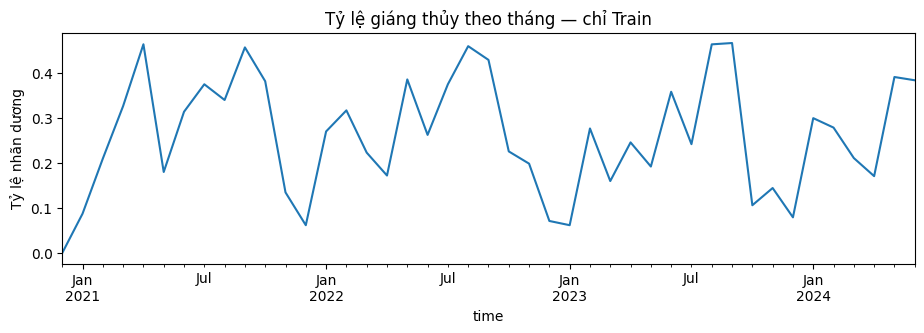

Phân bố Train: {0: 22273, 1: 8092}
Đặc trưng: ['temperature_c', 'humidity_pct', 'surface_pressure_hpa', 'cloud_cover_pct', 'wind_speed_ms', 'temperature_c_lag1h', 'temperature_c_lag3h', 'temperature_c_mean6h', 'temperature_c_change3h', 'humidity_pct_lag1h', 'humidity_pct_lag3h', 'humidity_pct_mean6h', 'humidity_pct_change3h', 'surface_pressure_hpa_lag1h', 'surface_pressure_hpa_lag3h', 'surface_pressure_hpa_mean6h', 'surface_pressure_hpa_change3h', 'cloud_cover_pct_lag1h', 'cloud_cover_pct_lag3h', 'cloud_cover_pct_mean6h', 'cloud_cover_pct_change3h', 'wind_speed_ms_lag1h', 'wind_speed_ms_lag3h', 'wind_speed_ms_mean6h', 'wind_speed_ms_change3h', 'hour_sin', 'hour_cos', 'day_of_year_sin', 'day_of_year_cos']


In [3]:
import matplotlib.pyplot as plt
splits = chronological_split(table)
for name, block in splits.items():
    print(name, len(block), block.index.min(), "→", block.index.max())
train_block = splits["train"]
monthly = train_block.target.resample("MS").mean()
ax = monthly.plot(figsize=(11, 3), title="Tỷ lệ giáng thủy theo tháng — chỉ Train")
ax.set_ylabel("Tỷ lệ nhãn dương")
plt.show()
print("Phân bố Train:", train_block.target.value_counts().to_dict())
print("Đặc trưng:", feature_names)


## 4. Smoke test với 365 ngày đầu, tối đa 20 boosting rounds

XGBoost dùng boosting rounds, không dùng epoch như mạng CNN. Smoke kiểm tra training,
calibration, threshold, biểu đồ, lưu/load và inference; không mở Test.
Baseline: dự đoán khô, tỷ lệ giáng thủy Train và trạng thái giáng thủy giờ trước.


{
  "xgboost_calibrated": {
    "rows": 869,
    "positive_rate": 0.2140391254315305,
    "threshold": 0.6399999999999999,
    "accuracy": 0.8481012658227848,
    "precision": 0.6134453781512605,
    "recall": 0.7849462365591398,
    "f1": 0.6886792452830188,
    "macro_f1": 0.7941113121392263,
    "average_precision": 0.6812508493554488,
    "pr_auc_trapezoid": 0.6834492188147976,
    "roc_auc": 0.9066893370487571,
    "brier_score": 0.11928406389250924,
    "log_loss": 0.37063942892558993,
    "confusion_matrix": [
      [
        591,
        92
      ],
      [
        40,
        146
      ]
    ],
    "classification_report": {
      "dry": {
        "precision": 0.936608557844691,
        "recall": 0.8653001464128843,
        "f1-score": 0.8995433789954338,
        "support": 683.0
      },
      "precipitation": {
        "precision": 0.6134453781512605,
        "recall": 0.7849462365591398,
        "f1-score": 0.6886792452830188,
        "support": 186.0
      },
      "accura

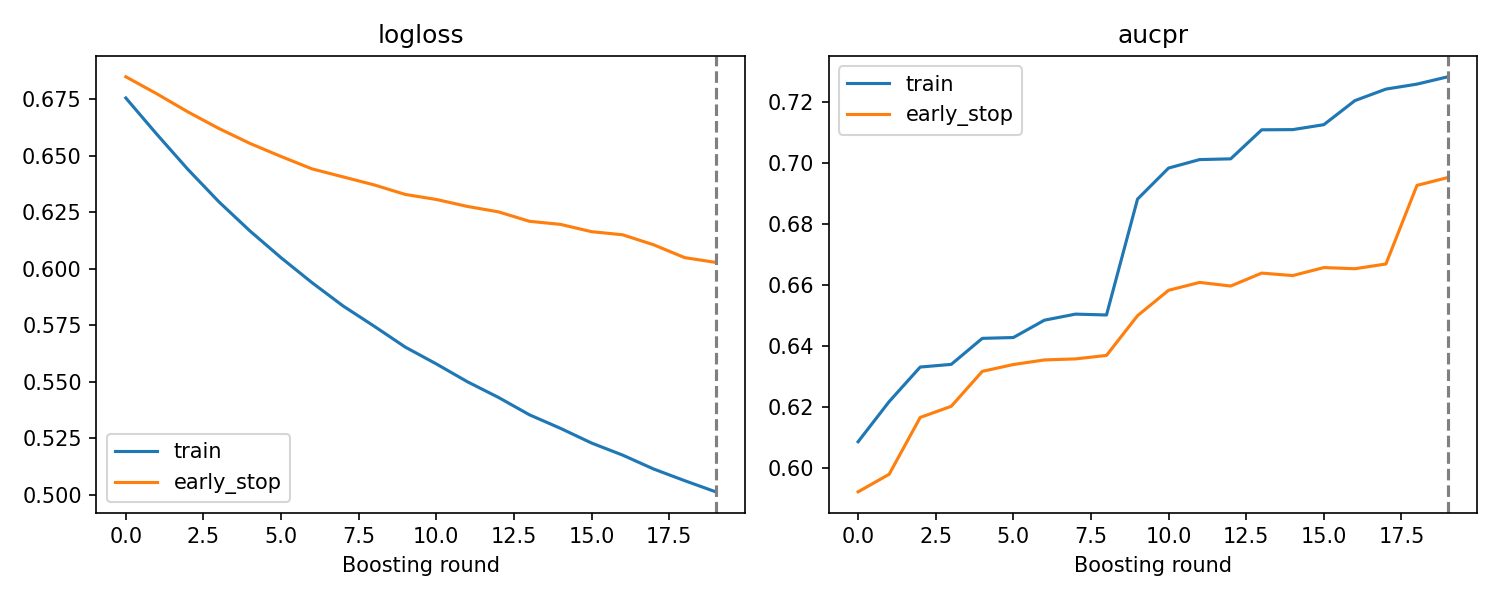

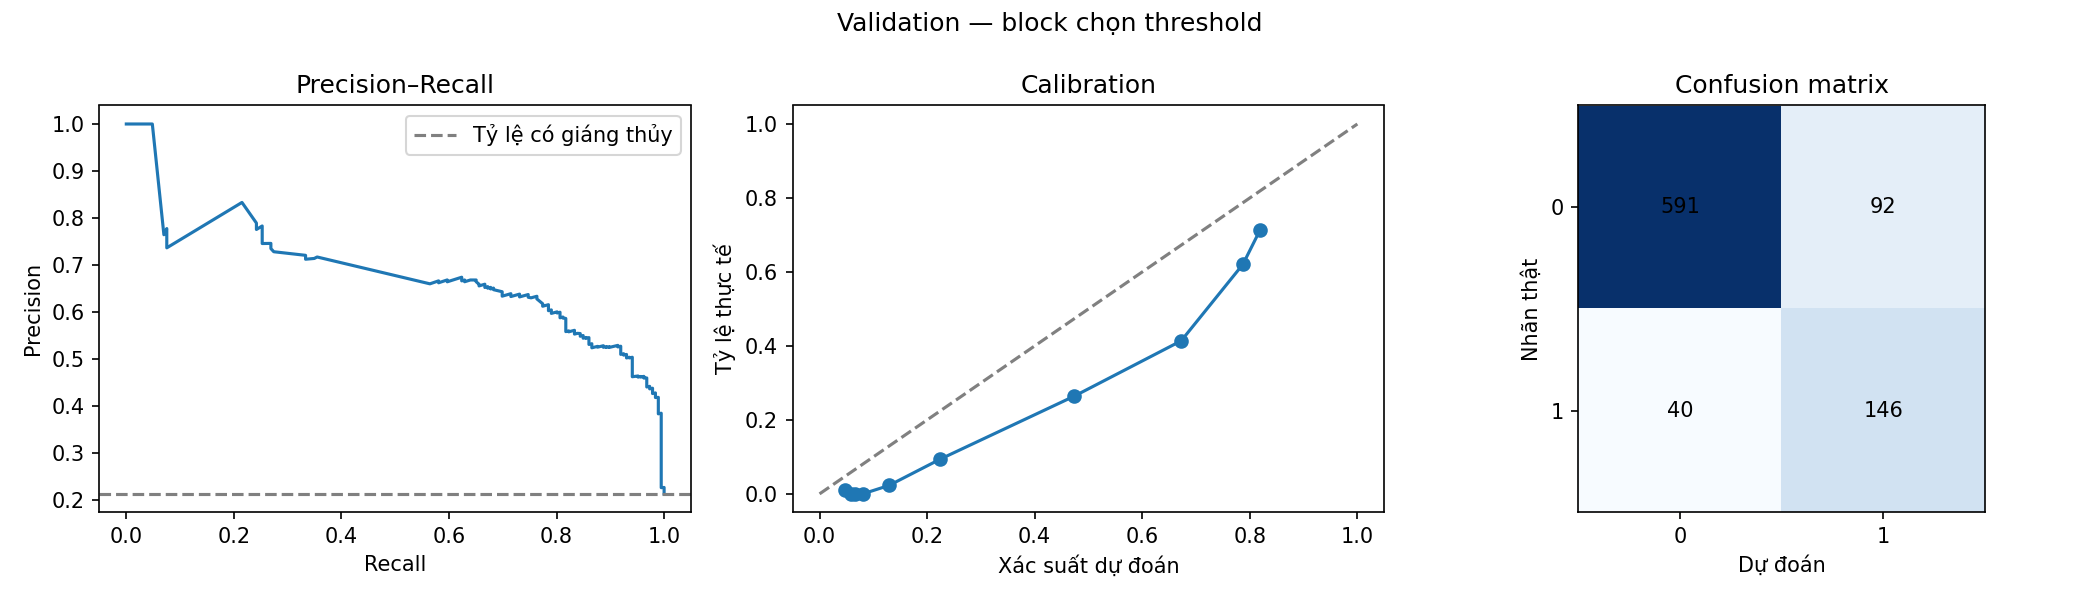

{'model_version': 'smoke-20261015T035547_799982Z', 'model_source': 'trained', 'is_mock': False, 'source': 'open_meteo_archive', 'smoke_only': True, 'production_ready': False, 'target': 'precipitation_next_60m', 'rain_proxy': True, 'rain_probability': 0.6545338034629822, 'threshold': 0.6399999999999999, 'prediction': 1, 'forecast_start': '2021-12-31T21:00:00+00:00', 'forecast_end': '2021-12-31T22:00:00+00:00', 'horizon_minutes': 60, 'predicted_at': '2026-10-15T03:55:50.950744+00:00', 'domain_shift': False, 'historical_replay': True}
Smoke thành công; chưa chạy đầy đủ hoặc đánh giá Test.


In [4]:
SMOKE_OK = False
smoke_table = table.loc[table.index < table.index.min() + pd.Timedelta(days=365)]
SMOKE_RUN = OUTPUT_ROOT / f"smoke-{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')}"
train(smoke_table, feature_names, SMOKE_RUN, feature_config=feature_config,
      config=TrainConfig(num_boost_round=20, early_stopping_rounds=5, smoke=True), provenance=source)
smoke_metrics = json.loads((SMOKE_RUN / "validation_metrics.json").read_text(encoding="utf-8"))
print(json.dumps(smoke_metrics, indent=2))
display(DisplayImage(filename=str(SMOKE_RUN / "history.png")))
display(DisplayImage(filename=str(SMOKE_RUN / "validation.png")))
predictor = RainPredictor(SMOKE_RUN)
reference = smoke_table.index[-1]
print(predictor.predict(hourly.loc[:reference], as_of=reference, source="open_meteo_archive"))
SMOKE_OK = True
print("Smoke thành công; chưa chạy đầy đủ hoặc đánh giá Test.")


## 5. Huấn luyện đầy đủ — bật sau smoke và rà soát

Đọc định nghĩa nhãn đại diện cho mưa và hạn chế nguồn trước khi bật.
Không có API/pump action trong pipeline. Mỗi run dùng thư mục mới, model lưu UBJ,
calibration và preprocessing lưu JSON. XGBoost CPU chạy nhanh; nếu ngắt trước khi xuất
artifact, tạo run mới và chạy lại với cùng seed. Không tự coi run dở là model hợp lệ.


{
  "xgboost_calibrated": {
    "rows": 5054,
    "positive_rate": 0.25643055005935894,
    "threshold": 0.36999999999999994,
    "accuracy": 0.814404432132964,
    "precision": 0.6226027397260274,
    "recall": 0.7013888888888888,
    "f1": 0.6596516690856313,
    "macro_f1": 0.7660336691456449,
    "average_precision": 0.7353323327765731,
    "pr_auc_trapezoid": 0.7352137882700539,
    "roc_auc": 0.8785030207162989,
    "brier_score": 0.11905801756439154,
    "log_loss": 0.37152502510027874,
    "confusion_matrix": [
      [
        3207,
        551
      ],
      [
        387,
        909
      ]
    ],
    "classification_report": {
      "dry": {
        "precision": 0.8923205342237062,
        "recall": 0.8533794571580628,
        "f1-score": 0.8724156692056583,
        "support": 3758.0
      },
      "precipitation": {
        "precision": 0.6226027397260274,
        "recall": 0.7013888888888888,
        "f1-score": 0.6596516690856313,
        "support": 1296.0
      },
     

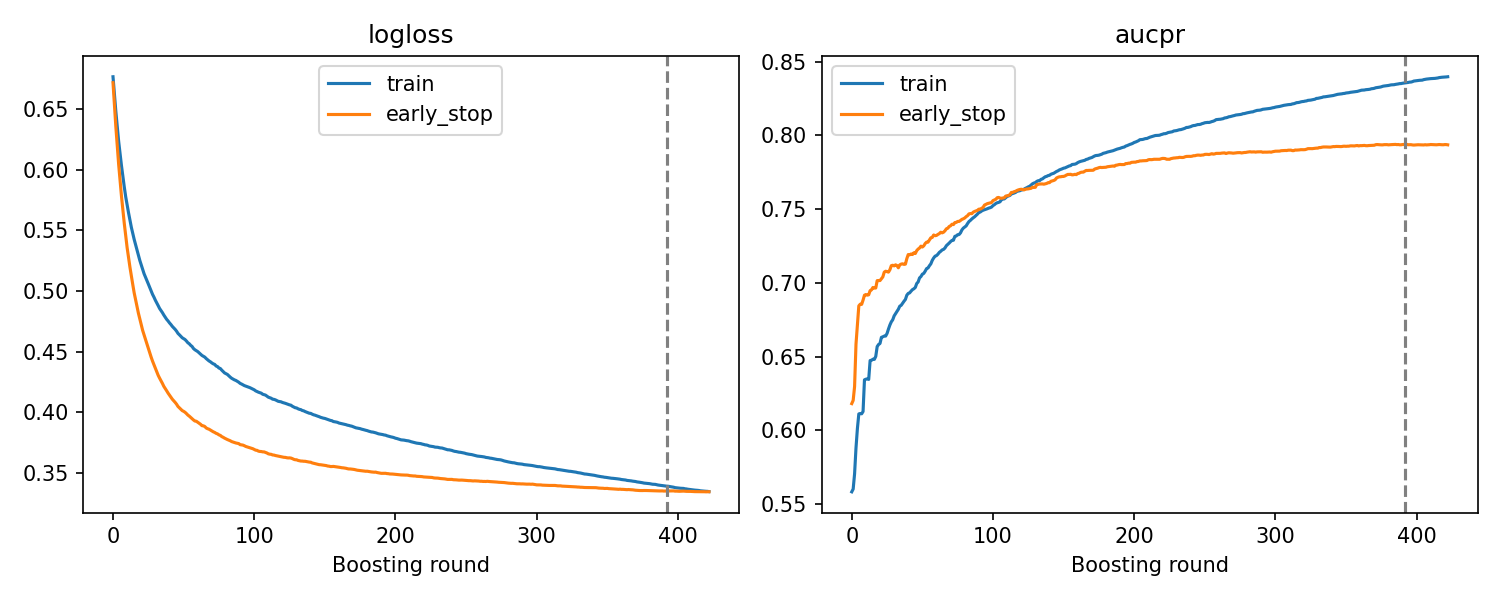

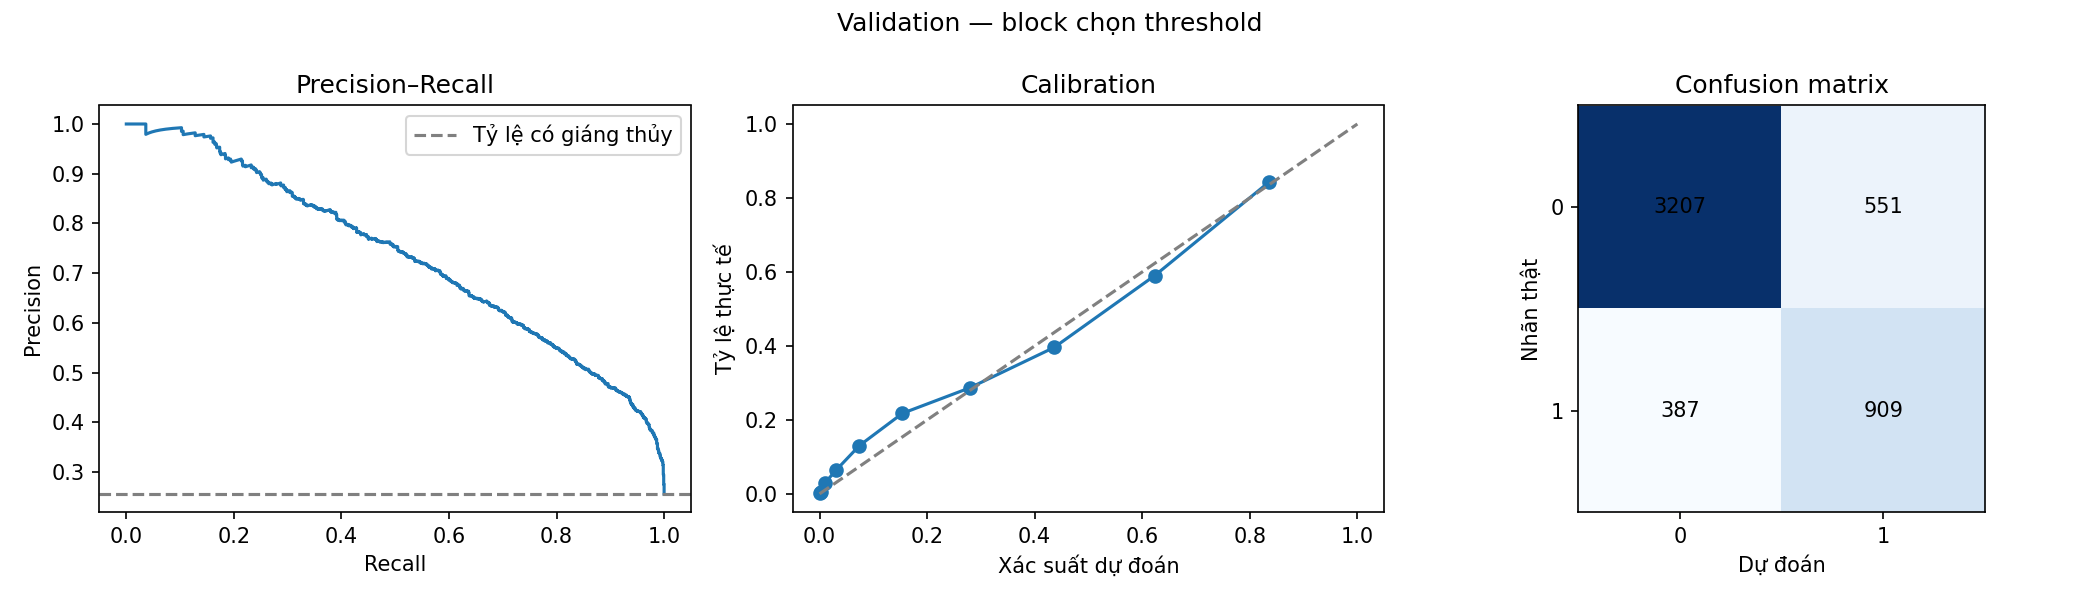

In [5]:
RUN_FULL_TRAINING = True
DATA_REVIEWED = True
FULL_RUN = None
if RUN_FULL_TRAINING:
    if not SMOKE_OK or not DATA_REVIEWED:
        raise RuntimeError("Cần smoke thành công và rà soát dữ liệu trước")
    FULL_RUN = OUTPUT_ROOT / f"xgboost-{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')}"
    train(table, feature_names, FULL_RUN, feature_config=feature_config,
          config=TrainConfig(seed=int(os.getenv("WEATHER_SEED", "42"))), provenance=source)
    print(json.dumps(json.loads((FULL_RUN / "validation_metrics.json").read_text(encoding="utf-8")), indent=2))
    display(DisplayImage(filename=str(FULL_RUN / "history.png")))
    display(DisplayImage(filename=str(FULL_RUN / "validation.png")))
else:
    print("Full training đang tắt.")


## 6. Test cuối cùng — không dùng để điều chỉnh hyperparameter

Chỉ mở sau khi chọn cấu hình. Nếu run đã có test_metrics.json, đọc lại báo cáo đã lưu.
Muốn đọc một run hoàn tất sau restart, gán FULL_RUN tới thư mục đó trên Drive.


{
  "xgboost_calibrated": {
    "rows": 5055,
    "positive_rate": 0.32660731948565774,
    "threshold": 0.36999999999999994,
    "accuracy": 0.8225519287833828,
    "precision": 0.7651195499296765,
    "recall": 0.6589945487583283,
    "f1": 0.7081028311096649,
    "macro_f1": 0.7903168695835379,
    "average_precision": 0.7972271821269376,
    "pr_auc_trapezoid": 0.7971443015841425,
    "roc_auc": 0.8812230382754176,
    "brier_score": 0.13519434811400075,
    "log_loss": 0.436066990316487,
    "confusion_matrix": [
      [
        3070,
        334
      ],
      [
        563,
        1088
      ]
    ],
    "classification_report": {
      "dry": {
        "precision": 0.8450316542802092,
        "recall": 0.9018801410105758,
        "f1-score": 0.8725309080574108,
        "support": 3404.0
      },
      "precipitation": {
        "precision": 0.7651195499296765,
        "recall": 0.6589945487583283,
        "f1-score": 0.7081028311096649,
        "support": 1651.0
      },
     

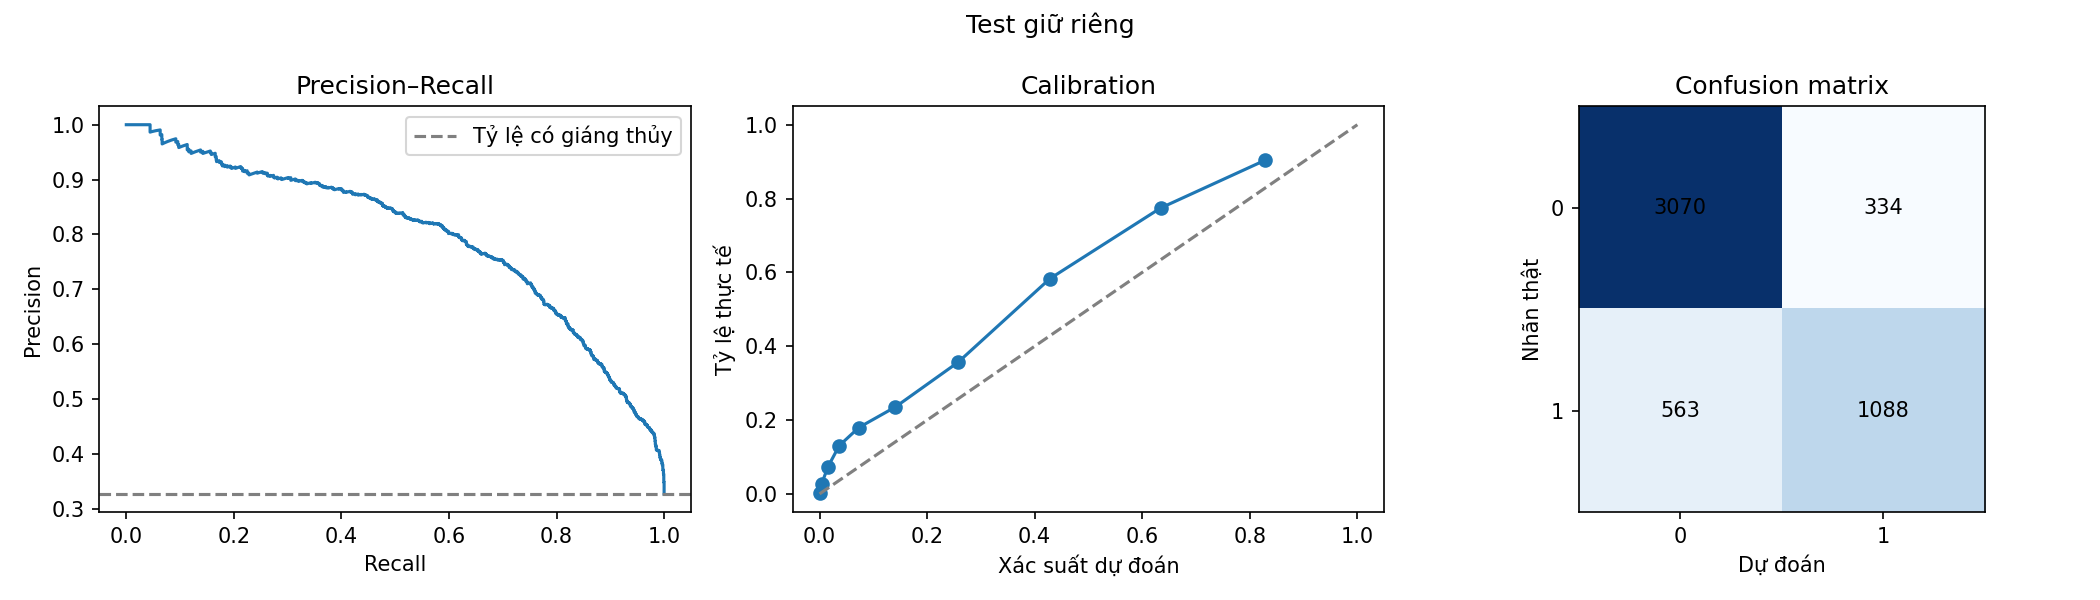

In [6]:
FINAL_EVALUATION = True
if FINAL_EVALUATION:
    if FULL_RUN is None:
        raise RuntimeError("Chưa có run đầy đủ")
    result = evaluate_test(table, FULL_RUN, allow_test=True)
    print(json.dumps(result, indent=2))
    display(DisplayImage(filename=str(FULL_RUN / "test.png")))
else:
    print("Test đang khóa.")


## 7. Inference hồi cứu và tích hợp sau này

`as_of` phải đúng giờ UTC, có đủ 6 giờ lịch sử và không chứa dữ liệu tương lai.
Ví dụ dưới là **phát lại lịch sử**, không phải dự báo thời tiết hôm nay.
OpenWeather cần các snapshot đã nhận trước từng mốc giờ, dữ liệu mới <=15 phút,
`units=metric`, áp suất `grnd_level`; không dùng `pressure` mực biển thay áp suất mặt đất.
Chế độ OpenWeather mặc định bị chặn vì chưa kiểm chứng domain shift. Xem README để thử adapter.
Chưa tích hợp vào backend; backend vẫn Mock AI và AI không trực tiếp điều khiển bơm.


In [7]:
ARTIFACT_DIR = FULL_RUN if FULL_RUN is not None else SMOKE_RUN
predictor = RainPredictor(ARTIFACT_DIR)
reference = table.index[-1]
prediction = predictor.predict(hourly.loc[:reference], as_of=reference, source="open_meteo_archive")
print(json.dumps(prediction, ensure_ascii=False, indent=2))
print("Artifact:", ARTIFACT_DIR)


{
  "model_version": "xgboost-20261015T035744_305966Z",
  "model_source": "trained",
  "is_mock": false,
  "source": "open_meteo_archive",
  "smoke_only": false,
  "production_ready": false,
  "target": "precipitation_next_60m",
  "rain_proxy": true,
  "rain_probability": 0.0034092760179191828,
  "threshold": 0.36999999999999994,
  "prediction": 0,
  "forecast_start": "2026-10-10T15:00:00+00:00",
  "forecast_end": "2026-10-10T16:00:00+00:00",
  "horizon_minutes": 60,
  "predicted_at": "2026-10-15T04:00:41.976104+00:00",
  "domain_shift": false,
  "historical_replay": true
}
Artifact: /content/drive/MyDrive/aiot-plant-care/weather-runs/xgboost-20261015T035744_305966Z
